In [46]:
#load packages I need
import os
import tools
import scanpy as sc
import pandas as pd
import dandelion as ddl
from tqdm import tqdm
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns
import numpy as np
import matplotlib.patheffects as pe

In [2]:
#set current directory 
os.chdir('/scratch/user/s4436039/scdata/Myeloid_Objects')
os.getcwd()

'/scratch/user/s4436039/scdata/Myeloid_Objects'

In [11]:
# read in data
data_mreg = sc.read_h5ad('20261124_mregDC_bbknn.h5ad')

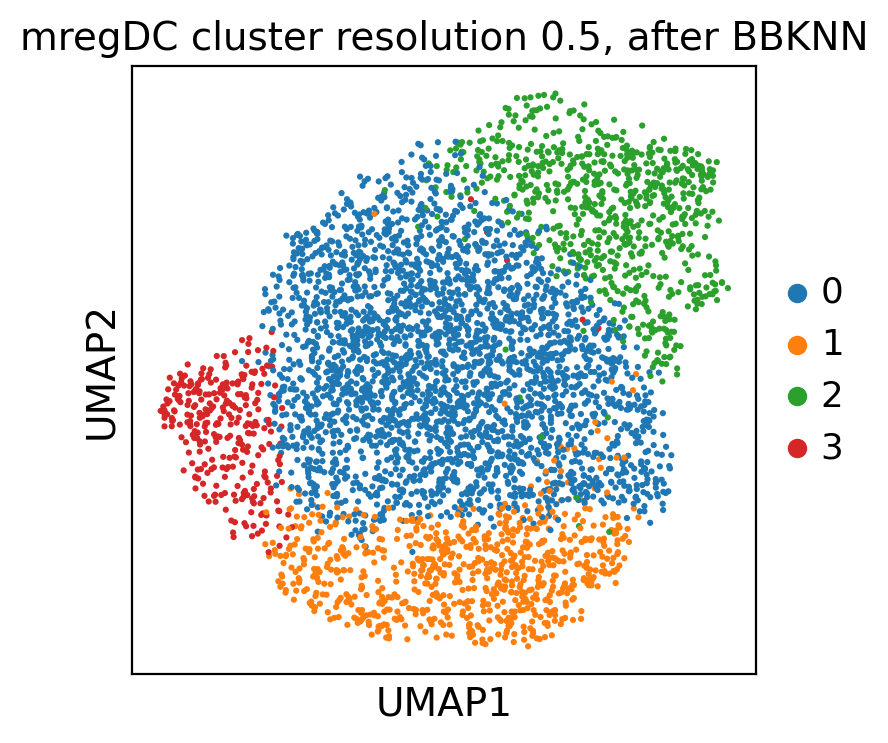

In [12]:
#plotting clusters 
with plt.rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(data_mreg, color=["2026_mreg_05"], ncols = 1, size=20, title="mregDC cluster resolution 0.5, after BBKNN")

In [ ]:
# read in data
#data = sc.read_h5ad('20250617_AllDC_bbknn.h5ad')
data = sc.read_h5ad('20260412_AllDC_Cytotrace.h5ad')

In [7]:
sc.set_figure_params(dpi=100, dpi_save=700, vector_friendly=True, format='svg') #only run when exporting umaps

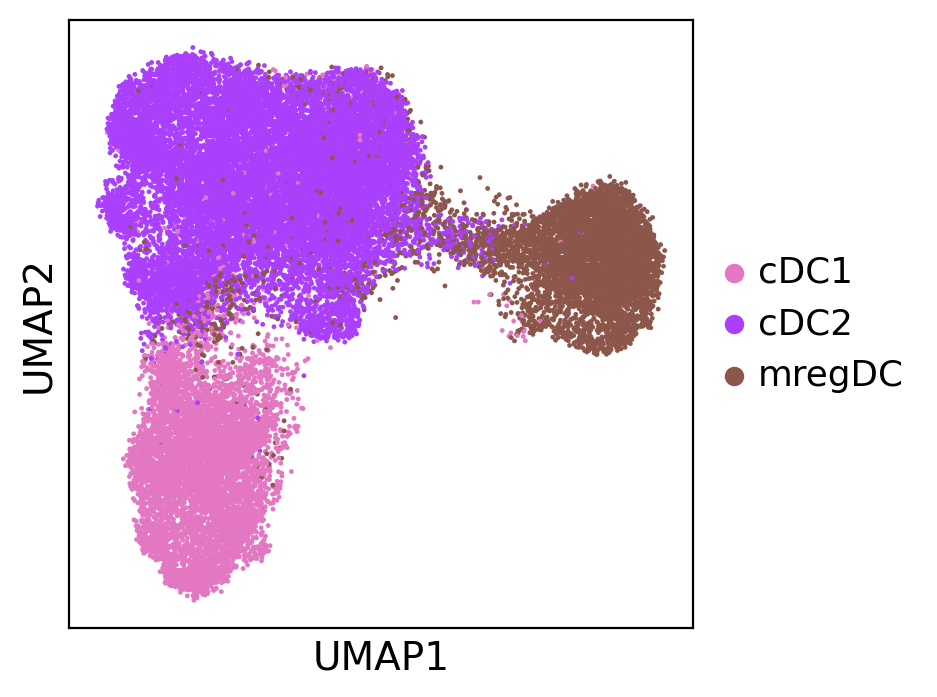

In [33]:
#export high res umap
with plt.rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(data, 
               color="NR_annotations_simple", 
               size=12,
               title="")

## Transfer mregDC sub-clusters to AllDC object

In [34]:
# check
data.obs["NR_annotations_simple"].value_counts()

NR_annotations_simple
cDC2      17166
cDC1       6670
mregDC     6051
Name: count, dtype: int64

In [35]:
# check
data_mreg.obs["2026_mreg_05"].value_counts()

2026_mreg_05
0    2784
1     776
2     750
3     298
Name: count, dtype: int64

In [36]:
# transfer mregDC cluster from mregDC object (2026_mreg_05) to AllDC 
# create new colum
data.obs["mregDC_sub"] = data.obs["NR_annotations_simple"].astype("string")
#replace relevant cells with mregDC subset annotations
data.obs.loc[data_mreg.obs_names, "mregDC_sub"] = (data_mreg.obs["2026_mreg_05"])

In [37]:
# check
data.obs["mregDC_sub"].value_counts()

mregDC_sub
cDC2      17166
cDC1       6670
0          2784
mregDC     1443
1           776
2           750
3           298
Name: count, dtype: Int64

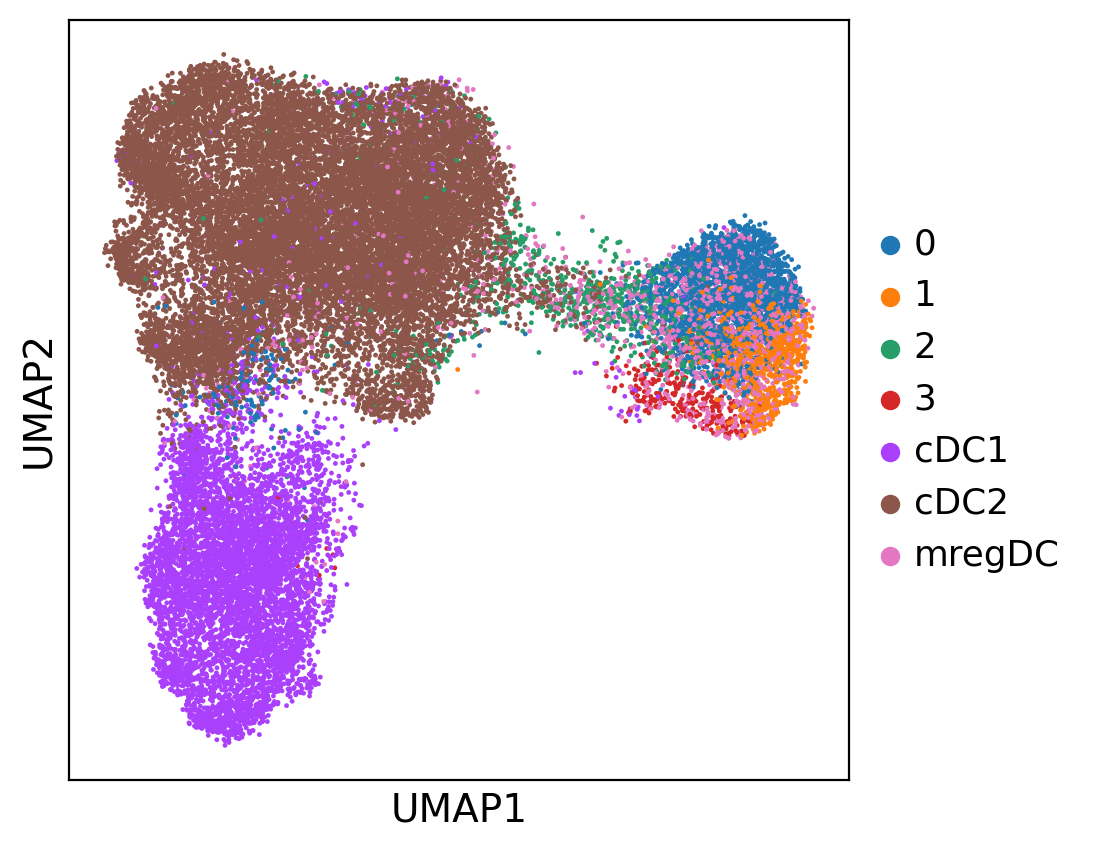

In [38]:
#export high res umap
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(data, 
               color="mregDC_sub", 
               size=12,
               title="")

In [39]:
# remove un-annotated mregDC
data = data[~(data.obs["mregDC_sub"] == "mregDC")].copy()

In [40]:
# check
data.obs["mregDC_sub"].value_counts()

mregDC_sub
cDC2    17166
cDC1     6670
0        2784
1         776
2         750
3         298
Name: count, dtype: int64

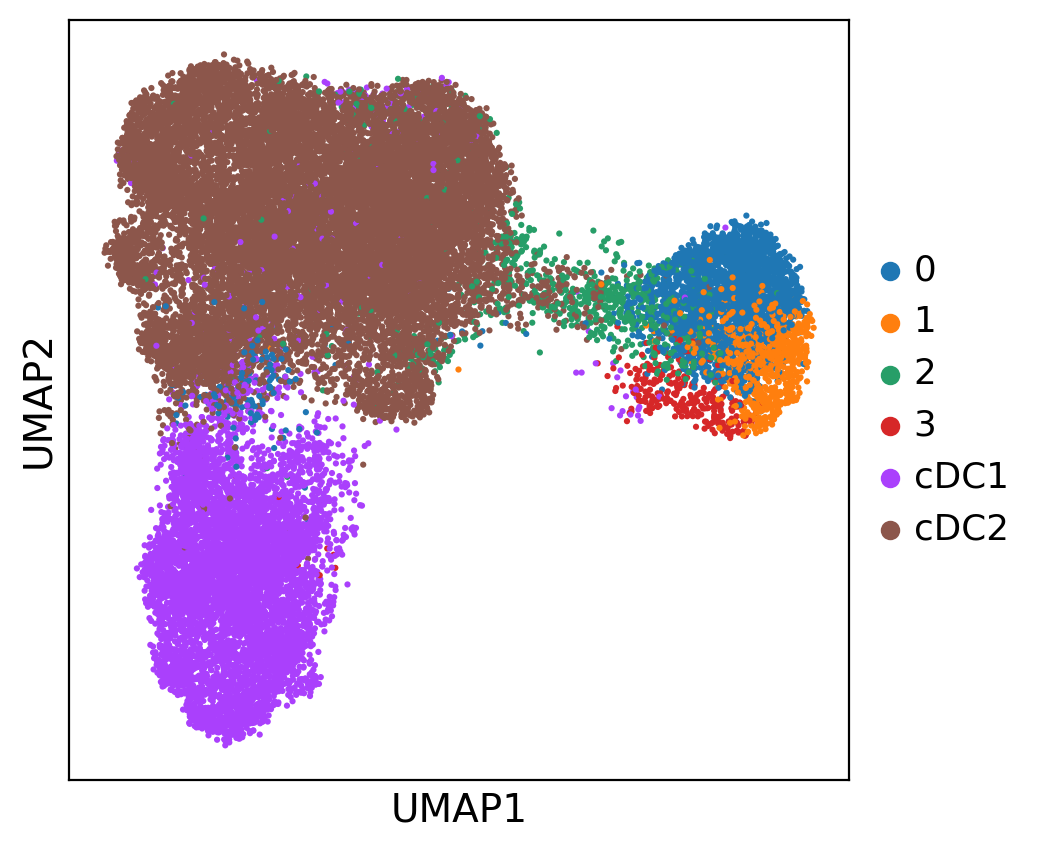

In [41]:
#export high res umap
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(data, 
               color="mregDC_sub", 
               size=20,
               title="")

In [65]:
# Set colours for mregDC_sub plot (pink, purple, brown):
#data.uns["NR_annotations_simple_colors"] = ['#e377c2', '#aa40fc', '#8c564b']  

data.uns["mregDC_sub_colors"] = ['#1f77b4', '#ff7f0e', '#2ca01c', '#d62728', '#e377c2', '#aa40fc'] 

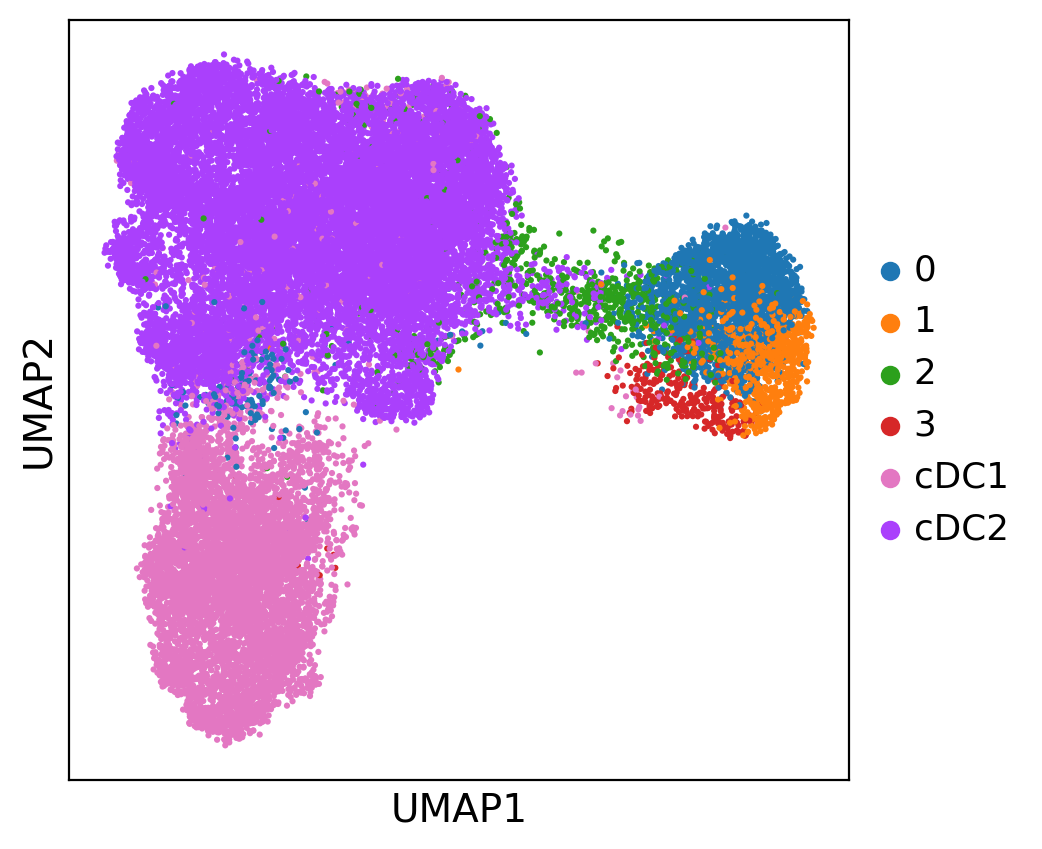

In [66]:
#export high res umap
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(data, 
               color="mregDC_sub", 
               size=20,
               title="")

In [67]:
data

AnnData object with n_obs × n_vars = 28444 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig', 'CytoTRACE_DC_Predicted_order_2026', 'mregDC_sub'
    var: 'name', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', '

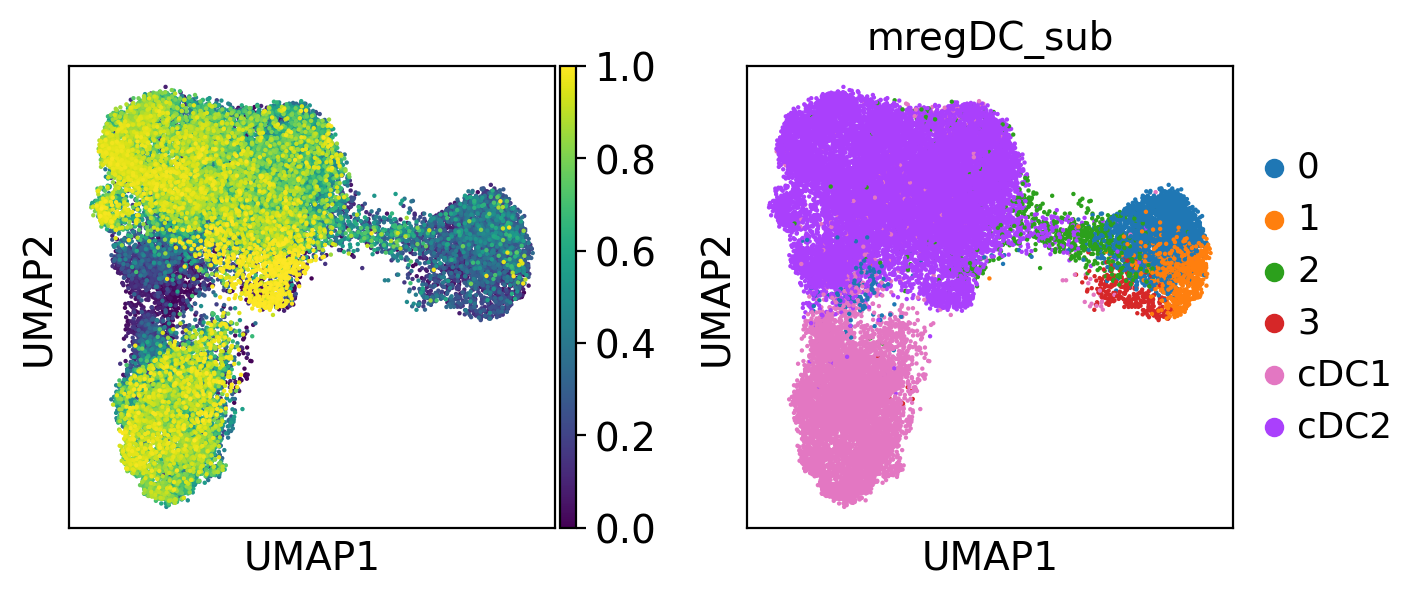

In [68]:
#plot cytotrace predictions. 1 --> less diff., 0 --> more diff.
with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(data, color=["CytoTRACE_DC_Predicted_order_2026","mregDC_sub"], size=10, title="")

## Run PAGA on this object

In [69]:
sc.tl.paga(data, groups="mregDC_sub")

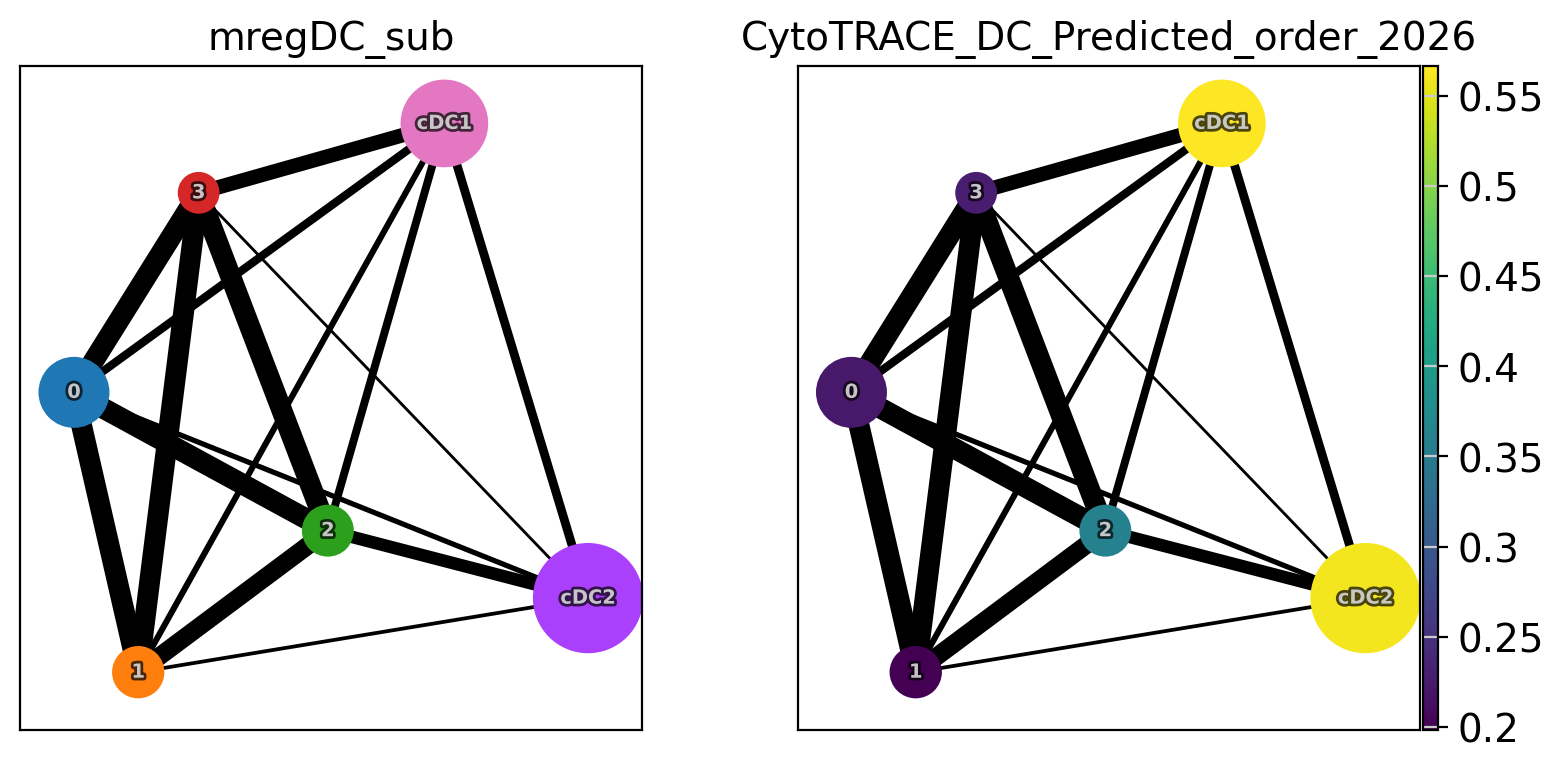

In [70]:
axes = sc.pl.paga(data, color=["mregDC_sub","CytoTRACE_DC_Predicted_order_2026"], threshold=0.03, node_size_scale=3, show=False)
# change text outline
for ax in axes:
    for text in ax.texts:
        text.set_fontsize(7)
        text.set_color("white")
        text.set_alpha(0.7)
        text.set_path_effects([
            pe.Stroke(linewidth=2, foreground='black'),  # outline
            pe.Normal()
        ])

plt.show()

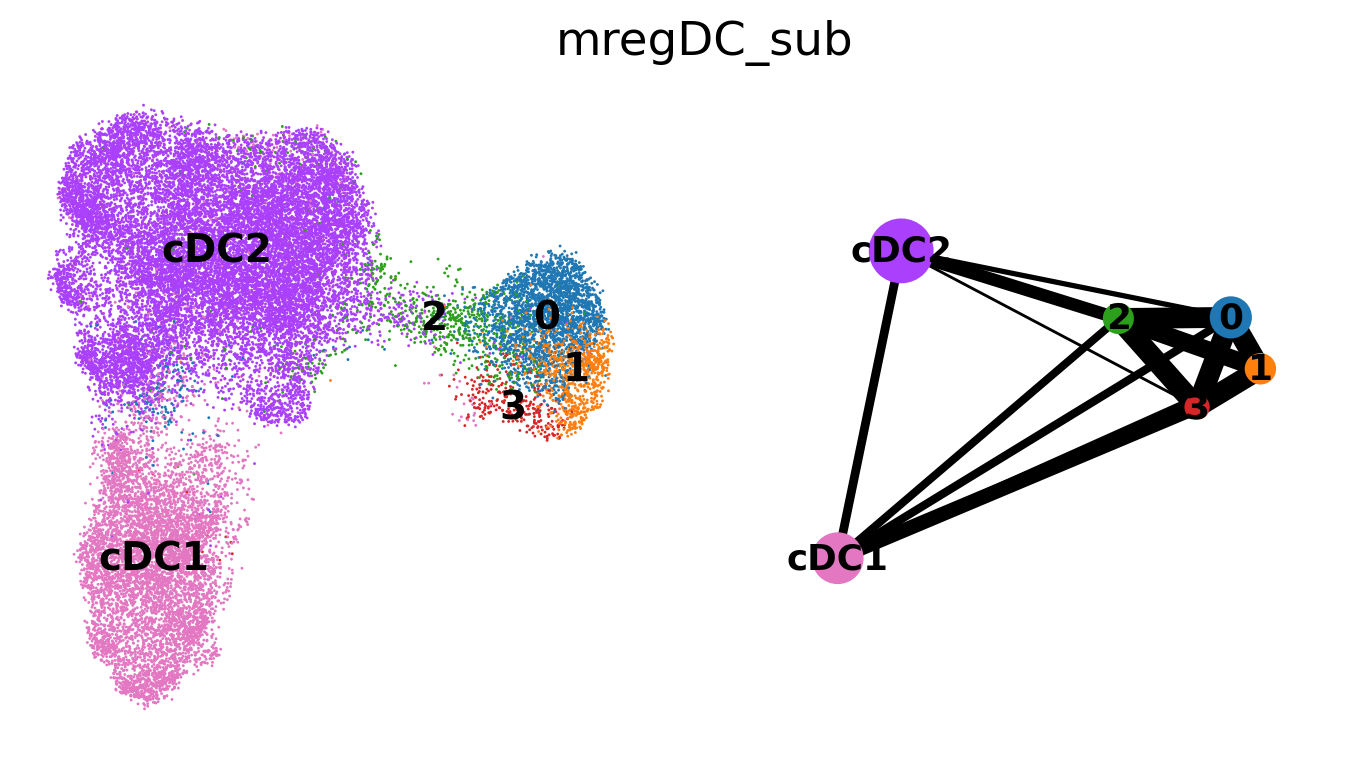

[<Axes: xlabel='UMAP1', ylabel='UMAP2'>, <Axes: >]

In [71]:
sc.pl.paga_compare(
    data,
    basis="umap",
    color="mregDC_sub"
)

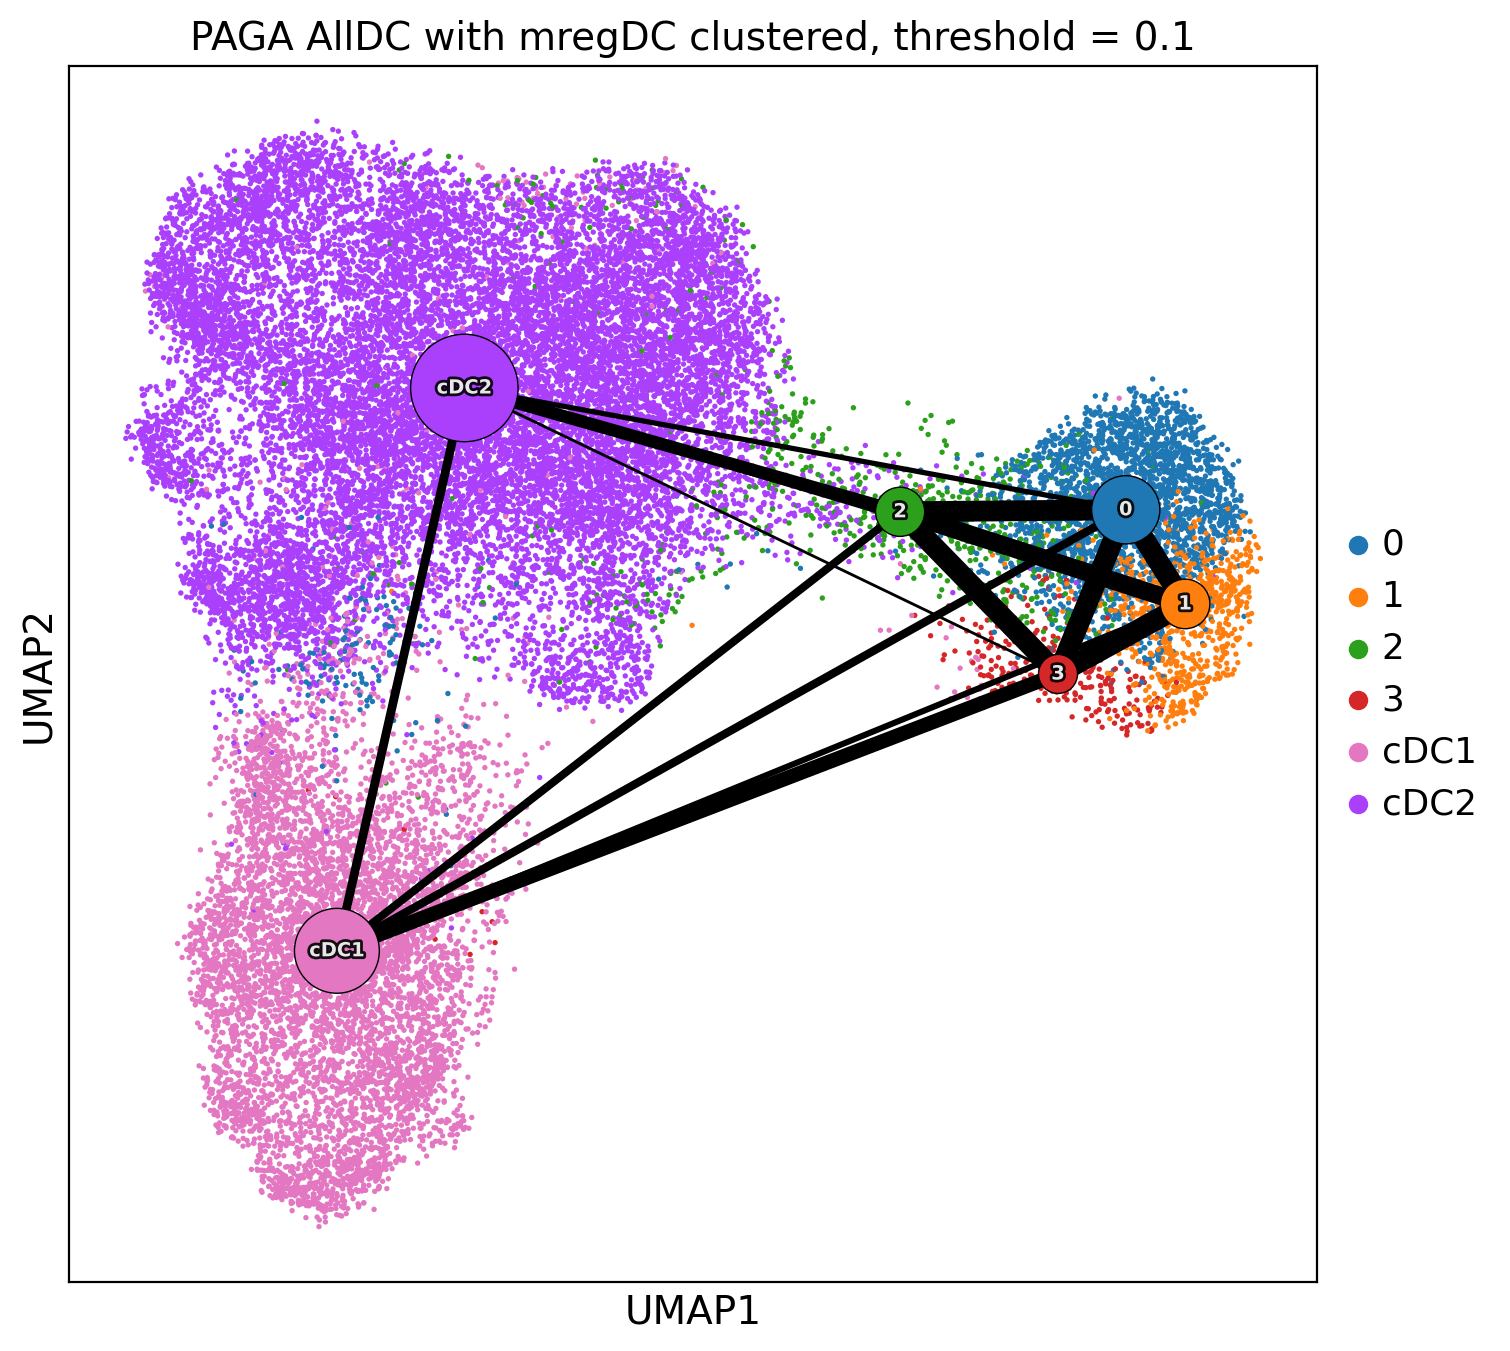

In [81]:
#Paper Figure:
fig, ax = plt.subplots(figsize=(8,8))

# UMAP
sc.pl.umap(
    data,
    color="mregDC_sub",
    ax=ax,
    size=15,
    title="PAGA AllDC with mregDC clustered, threshold = 0.1",
    show=False
)

# PAGA edges + nodes overlaid
sc.pl.paga(
    data,
    threshold=0.1,
    node_size_scale=3,
    edge_width_scale=1, 
    pos=data.uns["paga"]["pos"],
    ax=ax,
    show=False
)

#add outline around nodes otherwsie blends in to umap
paga_nodes = ax.collections[-1]
paga_nodes.set_edgecolor("black")
paga_nodes.set_linewidth(0.5)

#for text in ax.texts:
#    text.set_visible(False)

for text in ax.texts:
    text.set_fontsize(7)
    text.set_color("white")
    text.set_alpha(0.9)
    text.set_path_effects([
        pe.Stroke(linewidth=2, foreground='black'),  # outline
        pe.Normal()
    ])

plt.savefig("mregDC_PAGA_plot_clusters.svg", bbox_inches="tight")
plt.show()

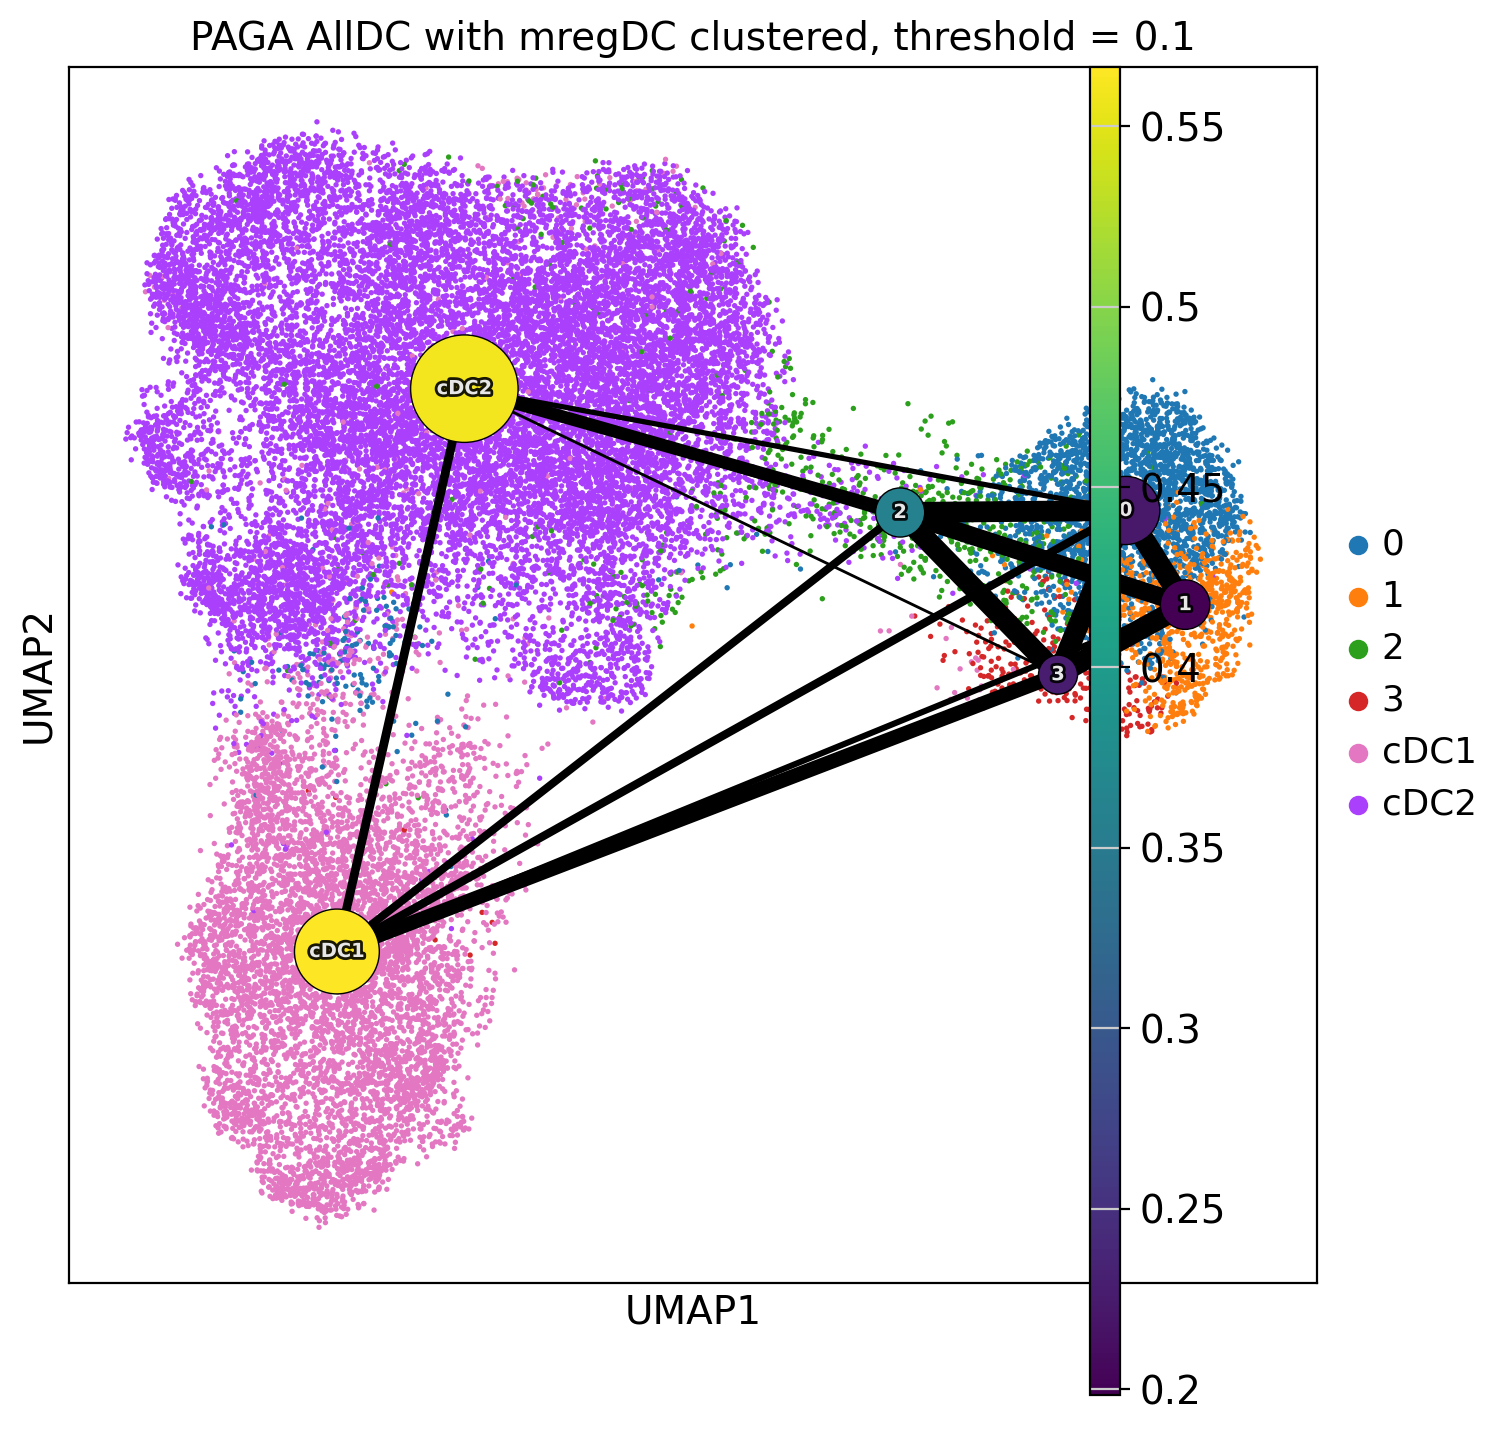

In [78]:
#Paper Figure:
fig, ax = plt.subplots(figsize=(8,8))

# UMAP
sc.pl.umap(
    data,
    color="mregDC_sub",
    ax=ax,
    size=15,
    title="PAGA AllDC with mregDC clustered, threshold = 0.1",
    show=False
)

# PAGA edges + nodes overlaid
sc.pl.paga(
    data,
    color="CytoTRACE_DC_Predicted_order_2026",
    threshold=0.1,
    node_size_scale=3,
    edge_width_scale=1, 
    pos=data.uns["paga"]["pos"],
    ax=ax,
    show=False
)

#add outline around nodes otherwsie blends in to umap
paga_nodes = ax.collections[-1]
paga_nodes.set_edgecolor("black")
paga_nodes.set_linewidth(0.5)

for text in ax.texts:
    text.set_fontsize(7)
    text.set_color("white")
    text.set_alpha(0.9)
    text.set_path_effects([
        pe.Stroke(linewidth=2, foreground='black'),  # outline
        pe.Normal()
    ])

plt.savefig("mregDC_PAGA_plot.svg", bbox_inches="tight")
plt.show()

# Compare mregDC subclusters to previously used ISG high subcluster

In [103]:
# read in data
data_ISG = sc.read_h5ad('20261126_All_ISG_annot.h5ad')

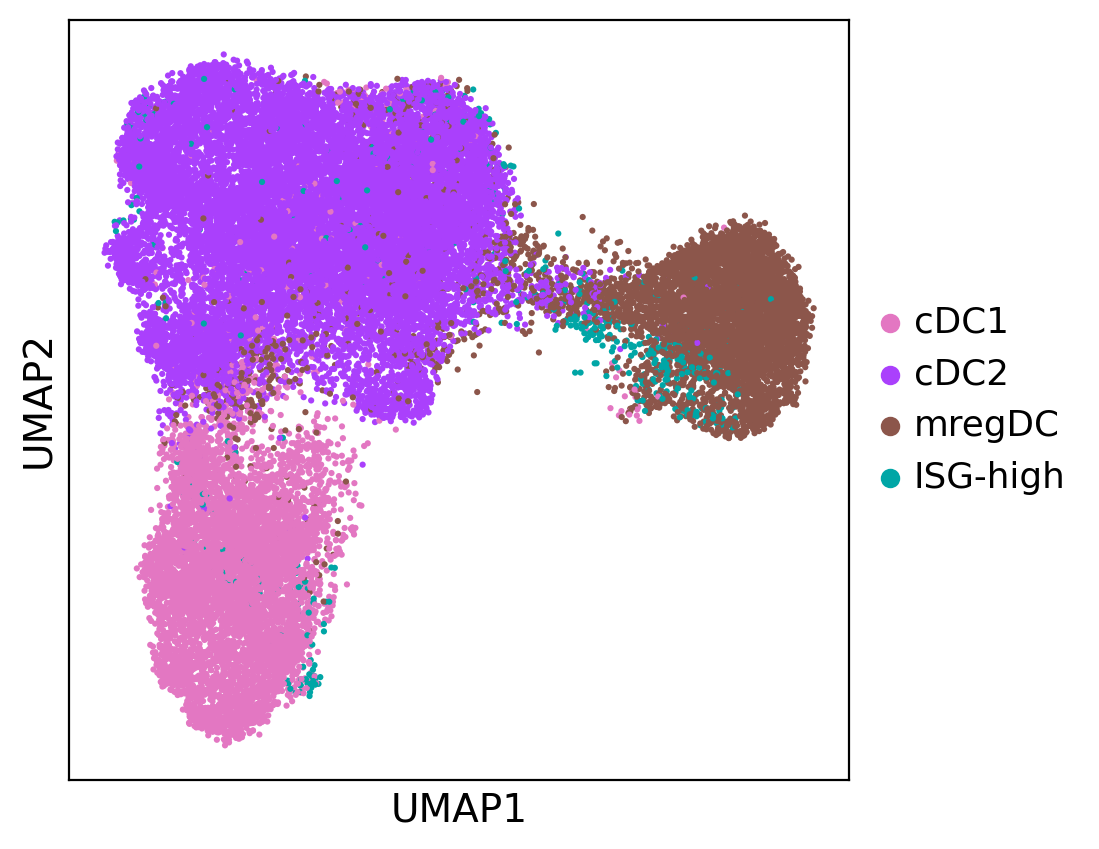

In [104]:
#plotting
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(data_ISG, 
               color="NR_annotations_ISG", 
               size=20,
               title="")

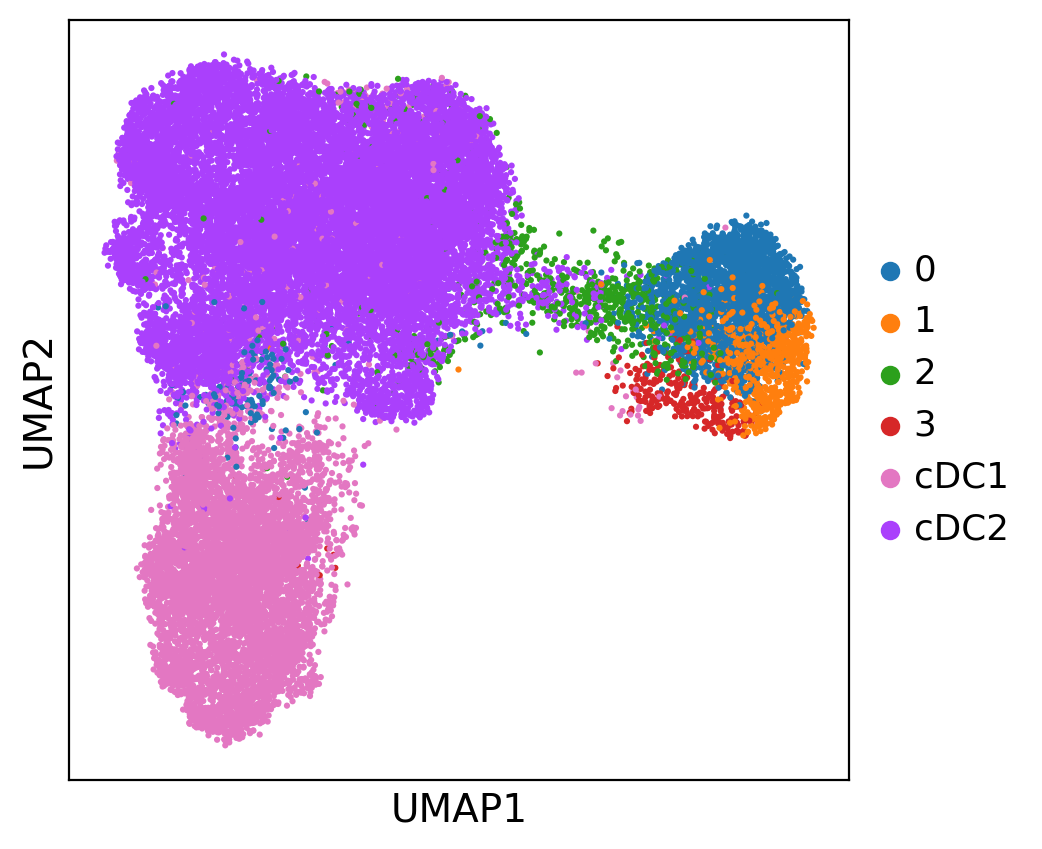

In [105]:
#export high res umap
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(data, 
               color="mregDC_sub", 
               size=20,
               title="")

In [111]:
# check
data_ISG.obs["NR_annotations_ISG"].value_counts()

NR_annotations_ISG
cDC2        17022
cDC1         6569
mregDC       5753
ISG-high      543
Name: count, dtype: int64

In [112]:
# check
data.obs["mregDC_sub"].value_counts()

mregDC_sub
cDC2    17166
cDC1     6670
0        2784
1         776
2         750
3         298
Name: count, dtype: int64

In [113]:
# copy meta column
data_ISG.obs["mregDC_sub"] = data_ISG.obs["NR_annotations_simple"].astype("string")

# Copy mregDC_sub from data to matching cells
shared_cells = data_ISG.obs_names.intersection(data.obs_names)

data_ISG.obs.loc[shared_cells, "mregDC_sub"] = (
    data.obs.loc[shared_cells, "mregDC_sub"].astype("string")
)

In [114]:
# check
data_ISG.obs["mregDC_sub"].value_counts()

mregDC_sub
cDC2      17166
cDC1       6670
0          2784
mregDC     1443
1           776
2           750
3           298
Name: count, dtype: Int64

In [115]:
pd.crosstab(
    data_ISG.obs["NR_annotations_ISG"],
    data_ISG.obs["mregDC_sub"],
)

mregDC_sub,0,1,2,3,cDC1,cDC2,mregDC
NR_annotations_ISG,,,,,,,
cDC1,0,0,0,0,6569,0,0
cDC2,0,0,0,0,0,17022,0
mregDC,2745,770,633,244,0,0,1361
ISG-high,39,6,117,54,101,144,82


In [118]:
pd.crosstab(
    data_ISG.obs["NR_annotations_ISG"],
    data_ISG.obs["NR_annotations_simple"],
    normalize="index",
).mul(100).round(1)

NR_annotations_simple,cDC1,cDC2,mregDC
NR_annotations_ISG,,,
cDC1,100.0,0.0,0.0
cDC2,0.0,100.0,0.0
mregDC,0.0,0.0,100.0
ISG-high,18.6,26.5,54.9


In [116]:
pd.crosstab(
    data_ISG.obs["NR_annotations_ISG"],
    data_ISG.obs["mregDC_sub"],
    normalize="index",
).mul(100).round(1)

mregDC_sub,0,1,2,3,cDC1,cDC2,mregDC
NR_annotations_ISG,,,,,,,
cDC1,0.0,0.0,0.0,0.0,100.0,0.0,0.0
cDC2,0.0,0.0,0.0,0.0,0.0,100.0,0.0
mregDC,47.7,13.4,11.0,4.2,0.0,0.0,23.7
ISG-high,7.2,1.1,21.5,9.9,18.6,26.5,15.1
